In [1]:
!nvidia-smi

Tue May 26 15:56:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Cell 1: Clean SAM3 install for Colab GPU runtime
# Run this once only.

!pip uninstall -y torch torchvision torchaudio numpy sam3 iopath ftfy >/dev/null 2>&1

!pip install -q \
  torch==2.10.0 \
  torchvision \
  --index-url https://download.pytorch.org/whl/cu128

!git clone https://github.com/facebookresearch/sam3.git /content/sam3

%cd /content/sam3
!pip install -q -e ".[notebooks]"

%cd /content

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 916.9/916.9 MB 1.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 106.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 98.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.4.4 which is incompatible.
Cloning into '/content/sam3'...
remote: Enumerating objects: 1177, done.
remote: Counting objects: 100% (86/86), done.
remote: Compressing objects: 100% (30/30), done.
remote: Total 1177 (delta 76), reused 56 (delta 56), pack-reused 1091 (from 3)
Receiving objects: 100% (1177/1177), 60.39 MiB | 6.38 MiB/s, done.
Resolving deltas: 100% (341/341), done.
/content/sam3
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to buil

In [1]:
# Cell 2: Check environment after restart

import torch
import torchvision
import numpy as np

print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("numpy:", np.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

from torchvision.ops import nms
print("torchvision.ops.nms OK")

from sam3.model_builder import build_sam3_image_model
from sam3.model.sam3_image_processor import Sam3Processor
print("SAM3 import OK")

torch: 2.10.0+cu128
torchvision: 0.25.0+cu128
numpy: 1.26.4
CUDA available: True
GPU: Tesla T4
torchvision.ops.nms OK


/content/sam3/sam3/model/model_misc.py:70: UserWarning: Flash Attention is disabled as it requires a GPU with Ampere (8.0) CUDA capability.
  OLD_GPU, USE_FLASH_ATTN, MATH_KERNEL_ON = get_sdpa_settings()


SAM3 import OK


/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [2]:
import os
from getpass import getpass
from huggingface_hub import login

os.environ["HF_TOKEN"] = getpass("HF_TOKEN: ")
login(token=os.environ["HF_TOKEN"], add_to_git_credential=False)

print("HF login done")

HF_TOKEN: ··········


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


HF login done


In [4]:
import os
from getpass import getpass
from huggingface_hub import login, hf_hub_download

if not os.environ.get("HF_TOKEN"):
    os.environ["HF_TOKEN"] = getpass("HF_TOKEN: ")

login(token=os.environ["HF_TOKEN"], add_to_git_credential=False)

ckpt_path = hf_hub_download(
    repo_id="facebook/sam3",
    filename="sam3.pt",
    token=os.environ["HF_TOKEN"],
)

print("checkpoint:", ckpt_path)
print("exists:", os.path.exists(ckpt_path))

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


sam3.pt:   0%|          | 0.00/3.45G [00:00<?, ?B/s]

checkpoint: /root/.cache/huggingface/hub/models--facebook--sam3/snapshots/3c879f39826c281e95690f02c7821c4de09afae7/sam3.pt
exists: True


In [6]:
import inspect
from sam3.model_builder import build_sam3_image_model

print(inspect.signature(build_sam3_image_model))

(bpe_path=None, device='cuda', eval_mode=True, checkpoint_path=None, load_from_HF=True, enable_segmentation=True, enable_inst_interactivity=False, compile=False)


In [8]:
from pathlib import Path

for p in Path("/content/sam3").rglob("*bpe*"):
    print(p)

/content/sam3/sam3/assets/bpe_simple_vocab_16e6.txt.gz


In [9]:
import torch
from pathlib import Path
from sam3.model_builder import build_sam3_image_model
from sam3.model.sam3_image_processor import Sam3Processor

bpe_path = "/content/sam3/sam3/assets/bpe_simple_vocab_16e6.txt.gz"

print("ckpt exists:", Path(ckpt_path).exists())
print("bpe exists:", Path(bpe_path).exists())

assert torch.cuda.is_available(), "CUDA is not available"

model = build_sam3_image_model(
    bpe_path=bpe_path,
    checkpoint_path=ckpt_path,
    device="cuda",
    eval_mode=True,
    load_from_HF=False,
)

processor = Sam3Processor(model)

print("SAM3 model loaded OK")

ckpt exists: True
bpe exists: True
SAM3 model loaded OK


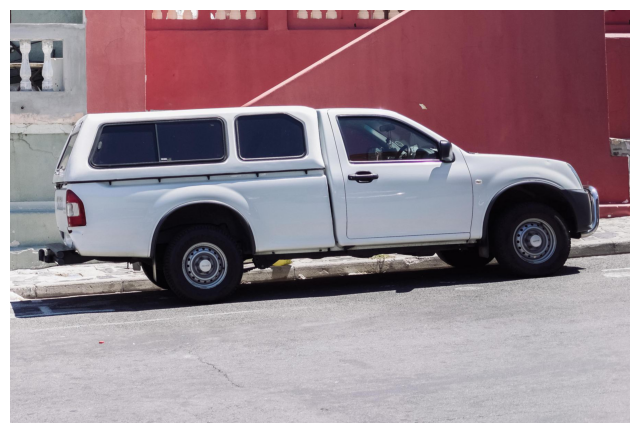

In [10]:
from PIL import Image
from pathlib import Path
import requests
import matplotlib.pyplot as plt

img_path = Path("/content/test_truck.jpg")
url = "https://raw.githubusercontent.com/facebookresearch/segment-anything/main/notebooks/images/truck.jpg"

r = requests.get(url)
r.raise_for_status()
img_path.write_bytes(r.content)

image = Image.open(img_path).convert("RGB")

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

In [14]:
import torch

model = model.to(dtype=torch.bfloat16)
model.eval()

print("model converted to bfloat16")

model converted to bfloat16


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:1367: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at /pytorch/aten/src/ATen/native/Copy.cpp:308.)
  return t.to(


In [16]:
import torch
from sam3.model_builder import build_sam3_image_model
from sam3.model.sam3_image_processor import Sam3Processor

bpe_path = "/content/sam3/sam3/assets/bpe_simple_vocab_16e6.txt.gz"

model = build_sam3_image_model(
    bpe_path=bpe_path,
    checkpoint_path=ckpt_path,
    device="cuda",
    eval_mode=True,
    load_from_HF=False,
    compile=False,
)

processor = Sam3Processor(model)

print("rebuilt clean fp32 model")

rebuilt clean fp32 model


In [18]:
import types
import torch

orig_forward_text = model.backbone.forward_text

def forward_text_fp32(self, *args, **kwargs):
    with torch.autocast(device_type="cuda", enabled=False):
        return orig_forward_text(*args, **kwargs)

model.backbone.forward_text = types.MethodType(forward_text_fp32, model.backbone)

print("patched forward_text to fp32")

patched forward_text to fp32


In [20]:
orig_forward_image = model.backbone.forward_image

def forward_image_fp32(self, *args, **kwargs):
    with torch.autocast(device_type="cuda", enabled=False):
        return orig_forward_image(*args, **kwargs)

model.backbone.forward_image = types.MethodType(forward_image_fp32, model.backbone)

print("patched forward_image to fp32")

patched forward_image to fp32


In [21]:
import torch
import numpy as np

with torch.inference_mode():
    state = processor.set_image(image)
    output = processor.set_text_prompt(state=state, prompt="truck")

masks = output["masks"]
boxes = output["boxes"]
scores = output["scores"]

print("num masks:", len(scores))
print("scores:", scores)
print("boxes:", boxes)

RuntimeError: mat1 and mat2 must have the same dtype, but got BFloat16 and Float